<a href="https://colab.research.google.com/github/rahs2015/mat422/blob/main/MAT_422_%7C_HW_1_4_1_4_Principal_Component_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 | HW 1.4.1-4: Principal Component Analysis

In [5]:
import numpy as np
import matplotlib.pyplot as plt

#1.4.1 SVD
The singular value decomposition is used to deconstruct a matrix into 3 manageable components. This is encompassed in its equation of U @ Σ @ V^t = A. U and V are orthonormal and along with Σ which is used to scale the singulular vectors.This was all accomplished by using a 4 by 3 matrix that were calculated separately and reconstructed to ensure validty.

Original matrix A:
[[4. 1. 3.]
 [2. 2. 1.]
 [5. 1. 4.]
 [1. 3. 0.]]


Singular Values:
[8.7639808  3.19058787 0.11309096]


Dimensions:
   U: (4, 3)
   Sigma: (3, 3)
   Vt: (3, 3)


U^T U:
[[ 1.00000000e+00 -2.00401395e-17 -9.33682629e-17]
 [-2.00401395e-17  1.00000000e+00 -8.75313129e-17]
 [-9.33682629e-17 -8.75313129e-17  1.00000000e+00]]


V V^T:
[[ 1.00000000e+00 -5.22937116e-17 -8.97276263e-17]
 [-5.22937116e-17  1.00000000e+00  3.59099976e-16]
 [-8.97276263e-17  3.59099976e-16  1.00000000e+00]]



Reconstruction of A:
[[4.00000000e+00 1.00000000e+00 3.00000000e+00]
 [2.00000000e+00 2.00000000e+00 1.00000000e+00]
 [5.00000000e+00 1.00000000e+00 4.00000000e+00]
 [1.00000000e+00 3.00000000e+00 5.75278822e-16]]


Reconstruction error:
3.990397793829187e-15

Reconstruction matches A: True




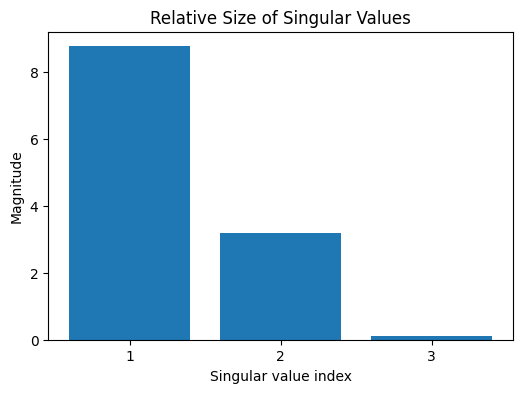

In [6]:
a = np.array([
    [4,1,3],
    [2,2,1],
    [5,1,4],
    [1,3,0],
], dtype=float)

U, s, vt = np.linalg.svd(a, full_matrices=False)

sig = np.diag(s)

a_hat = U @ sig @ vt

print("Original matrix A:")
print(a)

print("\n\nSingular Values:")
print(s)

print("\n\nDimensions:")
print("   U:", U.shape)
print("   Sigma:", sig.shape)
print("   Vt:", vt.shape)

print("\n\nU^T U:")
print(U.T @ U)

print("\n\nV V^T:")
print(vt.T @ vt)

print("\n\n\nReconstruction of A:")
print(a_hat)

reconstruction_error = np.linalg.norm(a - a_hat, ord="fro")

print("\n\nReconstruction error:")
print(reconstruction_error)

print("\nReconstruction matches A:", np.allclose(a, a_hat))

print()
print()
# Plot singular values

plt.figure(figsize=(6, 4))

plt.bar(
    np.arange(1, len(s) + 1), s
)

plt.xlabel("Singular value index")
plt.ylabel("Magnitude")
plt.title("Relative Size of Singular Values")
plt.xticks(np.arange(1, len(s) + 1))

plt.show()



#1.4.2 Low Rank Matrix Approx.
Building off the last question's SVD problem, a lower rank version of the matrix was created. The largest values are kept as k which come from SVD; this allows for a general trace of the matrix to be still kept intact. This brings in the rank approximation through calculating each rank's Forbenius error. Following this task, a plot is presented addressing how adding more ranks increases the accuracy.


--- Rank 1 approximation ---
[[3.92686983 1.43624008 2.88225439]
 [2.07203206 0.7578391  1.52083562]
 [4.96362997 1.81543178 3.64321836]
 [1.25395444 0.45862982 0.92038082]]

Rank: 1
Frobenius error: 3.1925915045756805


--- Rank 2 approximation ---
[[ 3.96489087  1.01249634  3.04160675]
 [ 1.95927676  2.01449457  1.04825986]
 [ 5.0380097   0.98647126  3.95495587]
 [ 1.02678148  2.99046771 -0.0317379 ]]

Rank: 2
Frobenius error: 0.11309095535173957


--- Rank 3 approximation ---
[[4.00000000e+00 1.00000000e+00 3.00000000e+00]
 [2.00000000e+00 2.00000000e+00 1.00000000e+00]
 [5.00000000e+00 1.00000000e+00 4.00000000e+00]
 [1.00000000e+00 3.00000000e+00 5.75278822e-16]]

Rank: 3
Frobenius error: 3.990397793829187e-15



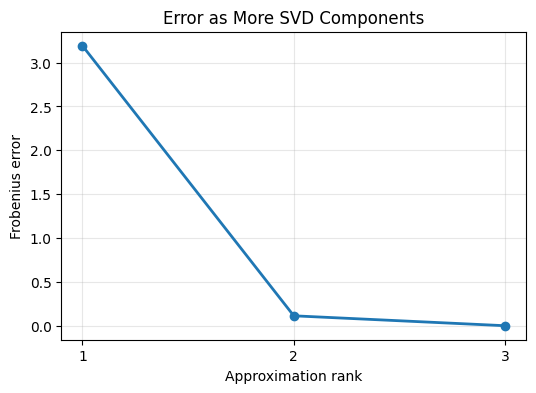

In [7]:
def make_approximation(U, values, vt, k):
    U_k = U[:, :k]
    s_k = np.diag(values[:k])
    vt_k = vt[:k, :]

    return U_k @ s_k @ vt_k


approximation_errors = []

for k in range(1, len(s) + 1):

    A_k = make_approximation(
        U,
        s,
        vt,
        k
    )

    error = np.linalg.norm(a - A_k, ord="fro")
    approximation_errors.append(error)

    print(f"\n--- Rank {k} approximation ---")
    print(A_k)
    print("\nRank:", np.linalg.matrix_rank(A_k))
    print("Frobenius error:", error)
    print()




plt.figure(figsize=(6, 4))
ranks = np.arange(1, len(s) + 1)

plt.plot(
    ranks,
    approximation_errors,
    marker="o",
    linewidth=2
)

plt.xlabel("Approximation rank")
plt.ylabel("Frobenius error")
plt.title("Error as More SVD Components")
plt.xticks(ranks)
plt.grid(alpha=0.3)
plt.show()

#1.4.3 Principal Component Analysis
With data that share strong commonaility, it becomes quite difficult to create arguments. However with a PCA, it is possible to discuss the variation of the matrix; this is done by applying SVD. This once again favors the strongest indication but is now applied to variation. This is accomplished by subtracting the means and which allows for the application of the SVD to be able to gain their PCA scores following the matrix multiplication of the principal directions.

Feature means:
[3.45 4.  ]

Centered data:
[[-2.25 -2.2 ]
 [-1.65 -1.6 ]
 [-1.35 -1.3 ]
 [-0.75 -0.8 ]
 [-0.35 -0.2 ]
 [ 0.35  0.1 ]
 [ 0.75  0.9 ]
 [ 1.35  1.2 ]
 [ 1.65  1.8 ]
 [ 2.25  2.1 ]]

Principal directions:
[[ 0.71504339  0.69908008]
 [ 0.69908008 -0.71504339]]

Singular values:
[6.33858092 0.29562132]

First three projected observations:
[[-3.14682379e+00  1.65270461e-04]
 [-2.29834971e+00 -9.41271347e-03]
 [-1.87411267e+00 -1.42017054e-02]]

Variance explained by each component:
[4.46417867 0.00971022]

Proportion of variance explained:
[0.99782958 0.00217042]

Total explained variance:
0.9999999999999999



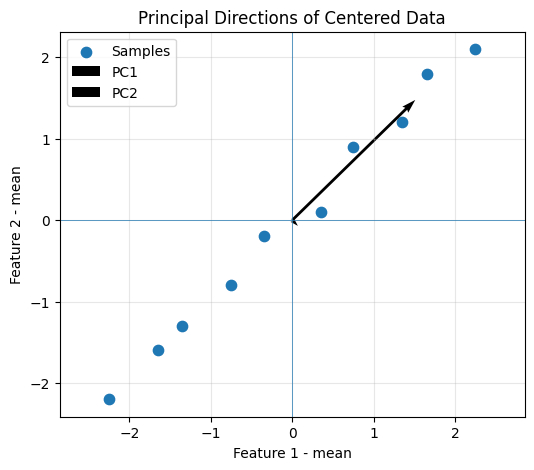

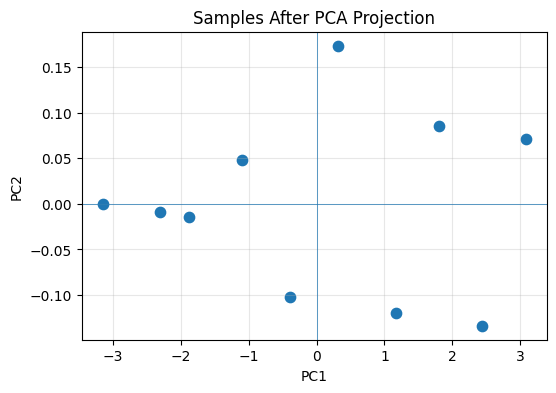

In [8]:
data = np.array([
    [1.2, 1.8],
    [1.8, 2.4],
    [2.1, 2.7],
    [2.7, 3.2],
    [3.1, 3.8],
    [3.8, 4.1],
    [4.2, 4.9],
    [4.8, 5.2],
    [5.1, 5.8],
    [5.7, 6.1]
], dtype=float)
feature_mean = data.mean(axis=0)
centered_data = data - feature_mean


U_data, data_sv, vt_data = np.linalg.svd(
    centered_data,
    full_matrices=False
)
principal_directions = vt_data


pca_scores = centered_data @ principal_directions.T


variance = (data_sv ** 2) / (len(data) - 1)
variance_ratio = variance / variance.sum()


print("Feature means:")
print(feature_mean)

print("\nCentered data:")
print(centered_data)

print("\nPrincipal directions:")
print(principal_directions)

print("\nSingular values:")
print (data_sv)

print("\nFirst three projected observations:")
print(pca_scores[:3])

print("\nVariance explained by each component:")
print(variance)

print("\nProportion of variance explained:")
print(variance_ratio)

print("\nTotal explained variance:")
print(variance_ratio.sum())
print()




plt.figure(figsize=(6, 5))

plt.scatter(
    centered_data[:, 0],
    centered_data[:, 1],
    s=55,
    label="Samples"
)

origin = np.array([0, 0])

pc1 = (
    principal_directions[0]
    * data_sv[0]
    / np.sqrt(len(data) - 1)
)

pc2 = (
    principal_directions[1]
    * data_sv[1]
    / np.sqrt(len(data) - 1)
)

plt.quiver(
    *origin,
    *pc1,
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.006,
    label="PC1"
)

plt.quiver(
    *origin,
    *pc2,
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.006,
    label="PC2"
)

plt.xlabel("Feature 1 - mean")
plt.ylabel("Feature 2 - mean")
plt.title("Principal Directions of Centered Data")

plt.axhline(0, linewidth=0.5)
plt.axvline(0, linewidth=0.5)

plt.grid(alpha=0.3)
plt.axis("equal")
plt.legend()

plt.show()
print()
print()
# Plot PCA scores

plt.figure(figsize=(6, 4))

plt.scatter(
    pca_scores[:, 0],
    pca_scores[:, 1],
    s=55
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Samples After PCA Projection")

plt.axhline(0, linewidth=0.5)
plt.axvline(0, linewidth=0.5)

plt.grid(alpha=0.3)

plt.show()

* I explained my sections in words before my code.
* I double checked my core numerical claims.
* I changed and/or extended at least one to make this homework my own.
* I ran this from to bottom without issues.
* I am saving this to github under my mat422 repository.